# 06 · The AI and LLM boom

When did AI show up in Vietnamese IT job postings, and how big has it become?

**Method.** Three signals, from most to least reliable. **AI roles** come from the title only (role `ai_ml`, see `03-roles`), so they do not depend on description length. **"AI" in the title** is the upper-case word AI in the job title. **LLM tools in the description** (LLM, GPT/OpenAI, LangChain, RAG, generative AI, AI agents, prompt engineering, vector databases, Hugging Face) depend on how much a source writes, so they are checked inside LinkedIn, whose descriptions keep the same length from 2023.

In [1]:
import sys
from pathlib import Path

# The notebook lives in notebooks/; the modules are one level up.
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd

import ai_trends as ai
import analysis as a

a.apply_style()
con = a.connect()
df = a.load_features(con)

## 1. AI roles

Share of IT postings whose role is AI/ML, for all sources, CareerBuilder and LinkedIn.

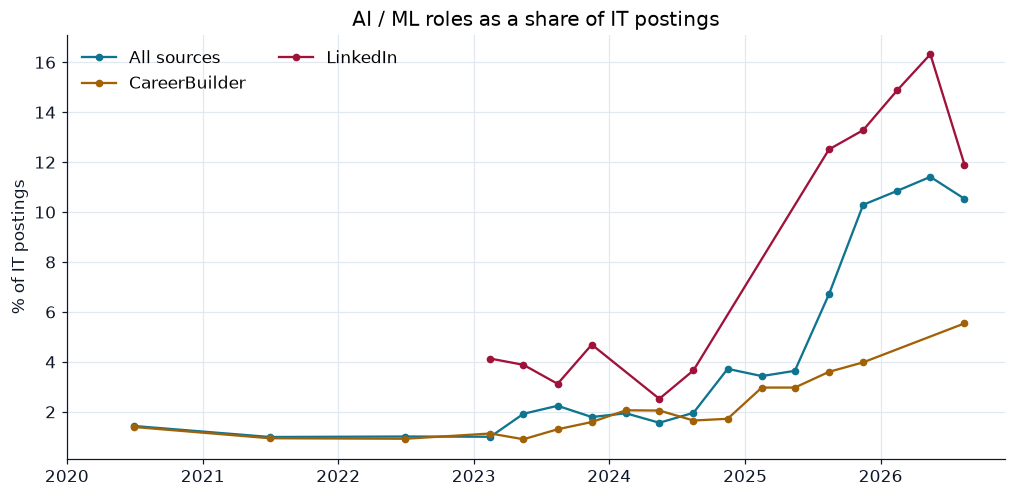

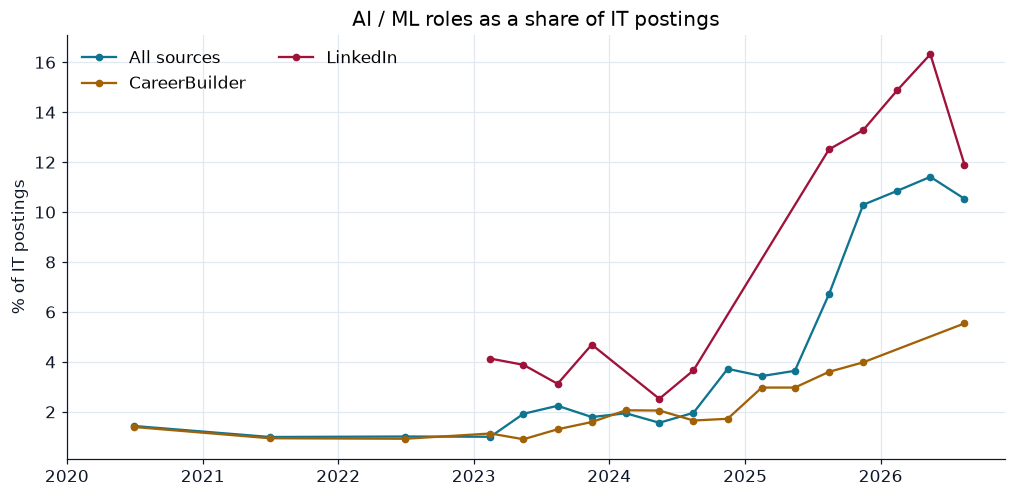

In [2]:
role_series = ai.signal_series(df, df.role == "ai_ml")
fig = a.trend_lines(role_series, "AI / ML roles as a share of IT postings", "% of IT postings")
a.save_chart(fig, "06-ai-roles")
rows = [f.assign(scope=n) for n, f in role_series.items()]
a.save_table(pd.concat(rows).drop(columns="period_date"), "06-ai-roles")
fig

## 2. "AI" in the title

Share of IT postings with the word AI in the job title.

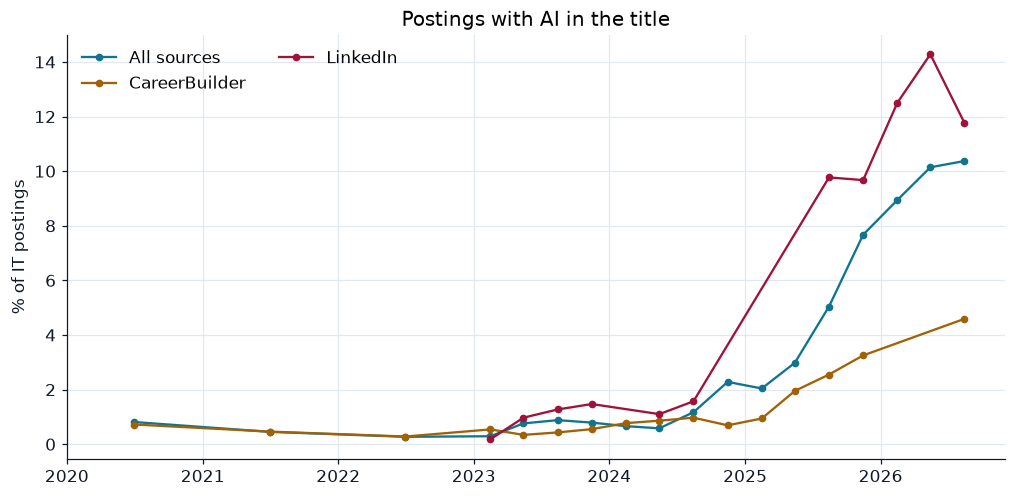

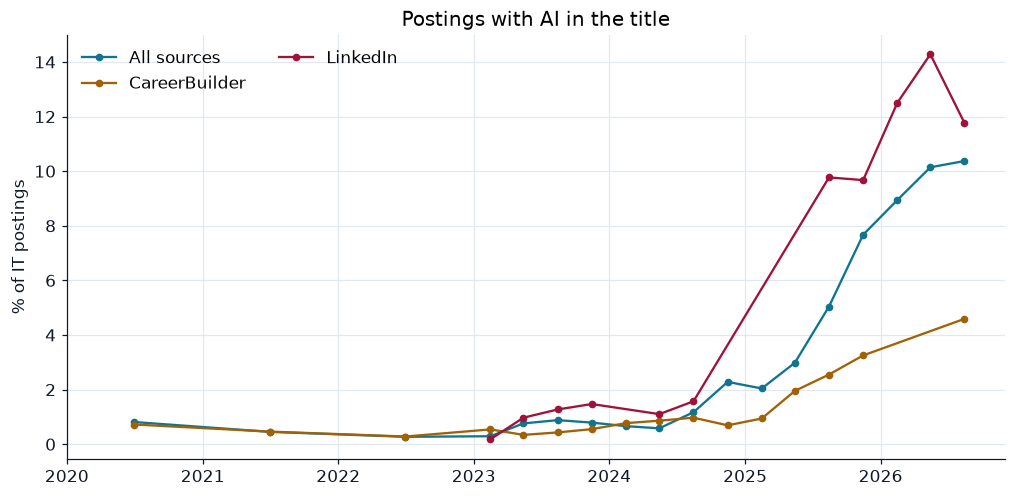

In [3]:
title_series = ai.signal_series(df, df.ai_in_title)
fig = a.trend_lines(title_series, "Postings with AI in the title", "% of IT postings")
a.save_chart(fig, "06-ai-in-title")
rows = [f.assign(scope=n) for n, f in title_series.items()]
a.save_table(pd.concat(rows).drop(columns="period_date"), "06-ai-in-title")
fig

## 3. LLM tools named in descriptions

Share of tech-naming postings that name at least one LLM-era tool. Compare all sources with LinkedIn: LinkedIn's descriptions stay the same length, so a rise there is not a description effect.

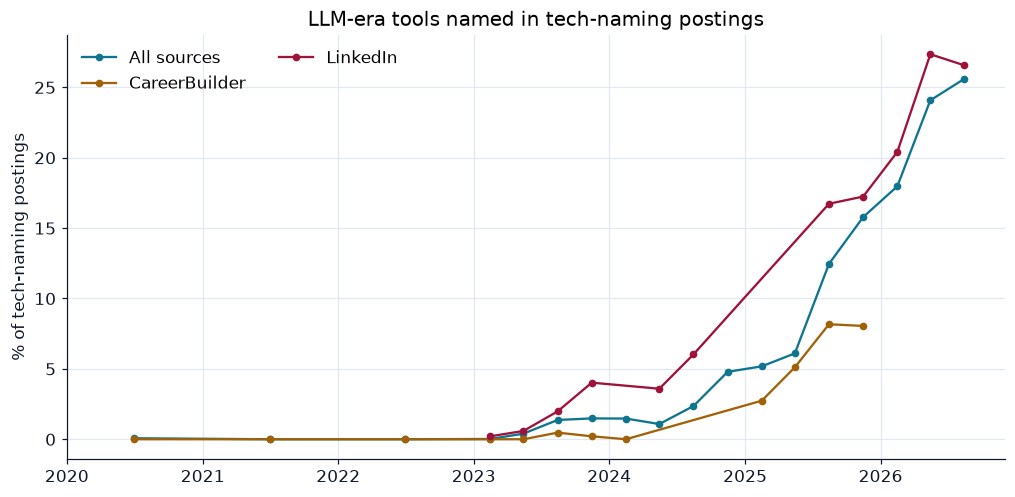

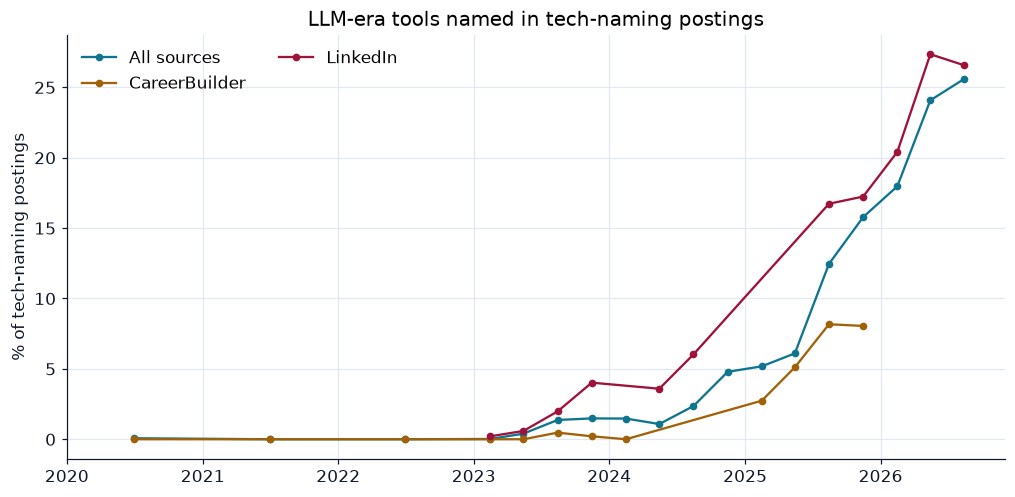

In [4]:
llm_series = ai.signal_series(df, ai.llm_flag(df), "named")
fig = a.trend_lines(
    llm_series, "LLM-era tools named in tech-naming postings", "% of tech-naming postings"
)
a.save_chart(fig, "06-llm-tools")
rows = [f.assign(scope=n) for n, f in llm_series.items()]
a.save_table(pd.concat(rows).drop(columns="period_date"), "06-llm-tools")
fig

In [5]:
first = ai.first_period_above(llm_series)
a.save_table(first, "06-llm-first-period")
first

,scope,first_period,share_then
0,All sources,2023-Q3,1.37
1,CareerBuilder,2025-Q1,2.74
2,LinkedIn,2023-Q3,1.98


## Findings

1. **AI roles took off during 2025, in every scope.** Share of IT postings whose role is AI/ML: all sources 1.0 % (2021 and 2023-Q1) → 3.4 % (2025-Q1) → 10.5 % (2026-Q3); CareerBuilder 0.9 % → 1.1 % → 3.0 % → 5.5 %; LinkedIn 4.1 % (2023-Q1) → 11.9 % (2026-Q3), peaking at 14.9 % in 2026-Q1.
2. **"AI" in the title tells the same story.** All sources: 0.3 % of postings (2023-Q1) → 2.0 % (2025-Q1) → 5.0 % (2025-Q3) → 10.4 % (2026-Q3). CareerBuilder: 0.9 % (2025-Q1) → 2.6 % (2025-Q3).
3. **LLM-era tools in descriptions.** They first reach 1 % of tech-naming postings in 2023-Q3 (all sources 1.4 %, LinkedIn 2.0 %). All sources: 5.2 % (2025-Q1), 12.5 % (2025-Q3), 18.0 % (2026-Q1), 25.6 % (2026-Q3). LinkedIn, whose descriptions stay the same length, goes from 3.6 % (2024-Q2) to 16.7 % (2025-Q3) to 26.6 % (2026-Q3), so this is not a description effect. CareerBuilder is later and smaller: 2.7 % (2025-Q1) → 8.2 % (2025-Q3).
4. **The size.** By early 2026, roughly one IT posting in nine has an AI role, one in twelve has "AI" in the title (late 2025 on, rising), and about a quarter of the postings that name technologies mention an LLM-era tool.
5. **Caveat.** These are mentions and titles, not proof of AI work: a posting that names an LLM tool or says "AI" in its title may only want familiarity. "GPT/OpenAI" also matches the words "gemini" and "claude".

**What this notebook cannot say:** how many AI jobs are real research or engineering roles, or how pay differs (the salary data is too thin after 2022).
